# Modeloplossing — Checkpoint KMeans & DBSCAN

Dit is de **modeloplossing** van het checkpoint. De bestandsnaam mag niet gewijzigd worden: de checks in `checks/` verwijzen naar dit notebook (via `CHECKPOINT_SOLUTIONS=1` wordt het als referentie gebruikt).

De opgave-versie (`week06/kmeans_dbscan_checkpoint_opgave.ipynb`) heeft dezelfde celstructuur met TODO's die de student invult. Gebruik overal `random_state=42` en `n_init=10` bij KMeans.


## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [2]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

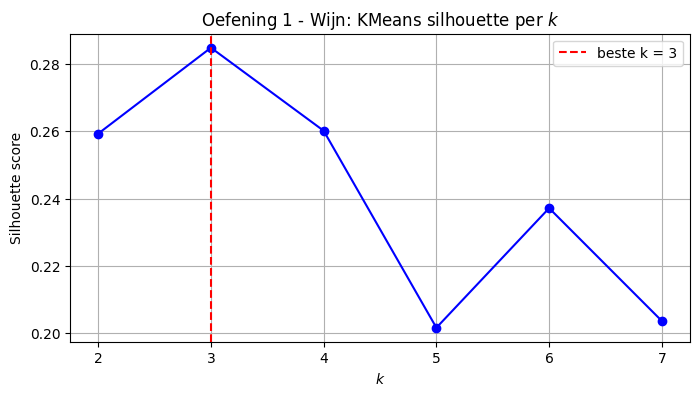

In [ ]:
import matplotlib.pyplot as plt

k_range_wine = list(range(2, 8))
sil_scores_wine = []
best_sil = -1.0
best_k_wine = 2
for k in k_range_wine:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(data_scaled)
    sil = silhouette_score(data_scaled, kmeans.labels_)
    sil_scores_wine.append(sil)
    if sil > best_sil:
        best_sil = sil
        best_k_wine = k
silhouette_wine = best_sil

# Silhouette per k



## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [2]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('../images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

image shape: (533, 800, 3)


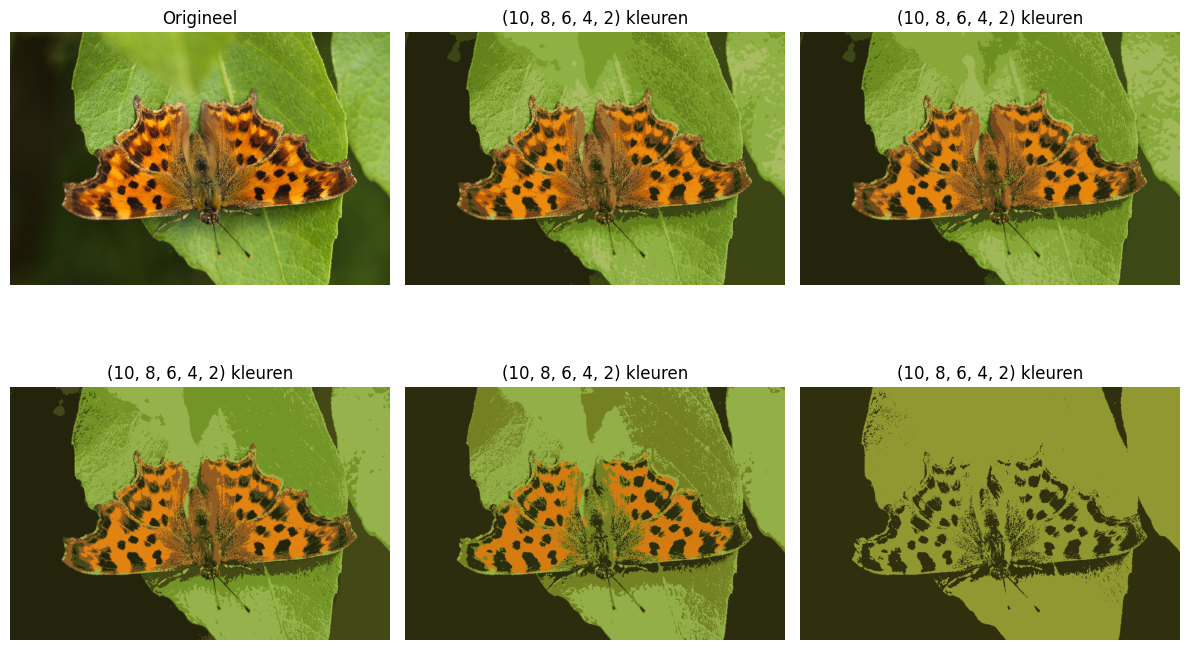

In [ ]:
n_colors = (10, 8, 6, 4, 2)
segmented_imgs = []
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10).fit(X)
    segmented_img = kmeans.cluster_centers_[kmeans.labels_]
    segmented_imgs.append(segmented_img.reshape(image.shape))

# Toon het origineel naast de gesegmenteerde versies
import matplotlib.pyplot as plt
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for i in range(6):
    axes.ravel()[i].axis('off')
axes.ravel()[0].imshow(image)
axes.ravel()[0].set_title('Origineel')
for idx, n_clusters in enumerate(n_colors):
    axes.ravel()[idx + 1].imshow(segmented_imgs[idx] / 255)
    axes.ravel()[idx + 1].set_title(f'{n_colors} kleuren')
plt.tight_layout()
plt.show()


## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

In [ ]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

iris = load_iris()
data_scaled = StandardScaler().fit_transform(iris.data)

k_range_iris = list(range(2, 6))
best_sil = -1.0
best_k_iris = 2
for k in k_range_iris:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(data_scaled)
    sil = silhouette_score(data_scaled, kmeans.labels_)
    if sil > best_sil:
        best_sil = sil
        best_k_iris = k
silhouette_iris = best_sil

# DBSCAN scoort op iris lager: de clusters zijn bolvormig en gelijkaardig dicht


## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

mall = pd.read_csv('../data/Mall_Customers.csv')
features = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
data_scaled = StandardScaler().fit_transform(features)

k_range_mall = list(range(2, 10))
best_sil = -1.0
best_k_mall = 5
for k in k_range_mall:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(data_scaled)
    sil = silhouette_score(data_scaled, kmeans.labels_)
    if sil > best_sil:
        best_sil = sil
        best_k_mall = k
silhouette_mall = best_sil

# DBSCAN scoort op mall lager: de clusters hebben sterk verschillende dichtheden


## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [ ]:
# Vraag 1: iris-clusters zijn bolvormig en gelijkaardig dicht -> KMeans scoort beter.
antwoord_iris = "A"

# Vraag 2: DBSCAN is beter bij niet-bolvormige clusters, verschillende dichtheden of outliers.
antwoord_dbscan = "A"
